# ALOHA: Advanced LOwer Hybrid Antenna

In this tutorial, we will create an ALOHA scenario for simple LH antenna.
Once the ALOHA scenario processed, we will post-process the ALOHA results.

In [5]:
from aloha import Scenario

The simplest way to create an ALOHA `Scenario` object is to open a TOML file which contains the ALOHA scenario parameters, for example:

In [10]:
my_scenario = Scenario("../scenarios/scenario_example.toml")
print(my_scenario)

{'comment': 'Simple scenario example for ALOHA', 'antenna': {'file': '8_active_waveguides.toml', 'excitation': {'f': 3700000000.0, 'experimental': False, 'power': [1, 1, 1, 1, 1, 1, 1, 1], 'phase': [0, 90, 180, 270, 0, 90, 180, 270], 'port': 'Q6B', 'pulse': 45155, 'avg_times': [7, 8]}}, 'plasma': {'solver': 'spectral_1D', 'spectral_1D': {'profile': 'bilinear', 'nb_evanescent_modes': 2, 'bilinear': {'vacuum_layer_length': 0.0, 'ne0': 5e+17, 'lambda_n': [0.002, 0.02], 'plasma_layer_length': 0.002, 'B0': 2.95, 'identical_profiles': True, 'infinite_waveguide': True, 'nz_min': -20, 'nz_max': 20, 'dnz': 0.01, 'ny_min': -2, 'ny_max': 2, 'dny': 0.1, 'z_min': -0.015, 'z_max': 0.075, 'nb_z': 60, 'x_max': 0.05, 'nb_x': 8}}}, 'options': {'debug': False}}


To run the scenario, use the `run` method:

In [11]:
my_scenario.run()

The results are stored in the `results` parameter of the scenario, which is a dictionnary which contains all the results calculated by ALOHA:

In [13]:
print(my_scenario.results.keys())

dict_keys(['S_plasma', 'rac_Zhe', 'S_ant_11', 'S_ant_12', 'S_ant_21', 'S_ant_22', 'a_acces', 'a_plasma', 'b_plasma', 'RC_mouth', 'S_acces', 'b_acces', 'CoeffRefPuiss', 'RC', 'ny', 'nz', 'nz0', 'dny', 'dnz', 'dP', 'dP_nz'])


For example, let's plot the antenna spectrum:

In [8]:
import matplotlib.pyplot as plt

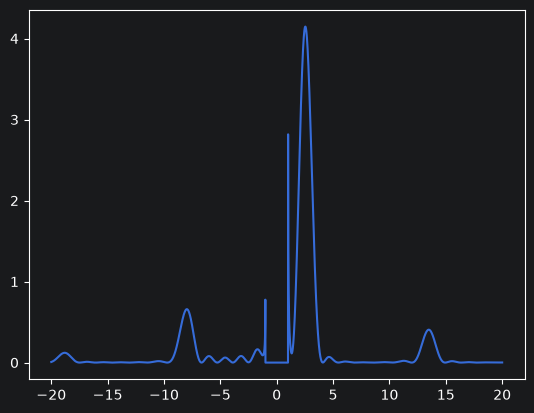

In [9]:
fig, ax = plt.subplots()
ax.plot(my_scenario.results["nz"], abs(my_scenario.results["dP_nz"]))

In [17]:
my_sc2 = Scenario("../scenarios/scenario_example.toml")
my_sc2.scenario["plasma"]["spectral_1D"]["nb_evanescent_modes"] = 0
my_sc2.run()

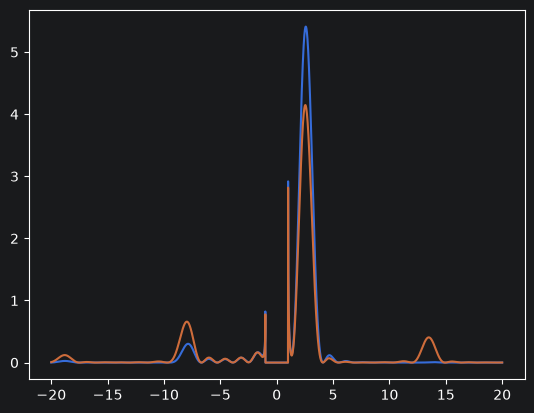

In [18]:
fig, ax = plt.subplots()
ax.plot(my_sc2.results["nz"], abs(my_sc2.results["dP_nz"]))
ax.plot(my_scenario.results["nz"], abs(my_scenario.results["dP_nz"]))



% if you run this matlab function, it will generate a matlab structure which
% is an 'ALOHA scenario'. This matlab structure contains all the
% parameters and informations needed by ALOHA to make its calculations.
% This structure is also the input variable of the aloha_scenario function.

disp('Please have a look at the My_first_aloha_scenario.m file first');
pause

% This tutorial contains two example scenarios
% - tutorial_aloha_scenarioC4_defaultExcitation.m
% - tutorial_aloha_scenarioC4_manualExcitation.m
% The C4 antenna is described internally in the ALOHA code. One can use
% the default excitation for this antenna or to define its own power and phase excitation.
%
% First, let's run ALOHA on the default excitation scenario.
% The default C4 ALOHA excitation  correspond to a power density of
% 25MW/m^2 at the mouth. In ALOHA, only half of the Tore Supra are modeled.
% Since there is 8 modules (8 upper or 8 lower), this means that the default
% power input in a module is 2.6725MW/(2*8) Watts. This value comes from
% the active waveguide surface at the mouth and the 25MW/m^2 power density.
%
sc_defaultExcitation = aloha_scenario(tutorial_aloha_scenarioC4_defaultExcitation);
% We can read in the command line that the average reflection coefficient is 5.07%
% and the peak n// is 1.72

% Now, let's run ALOHA on the manual excitation. In the manual excitation
% scenario, I've put a -150° phase shift between module, and 300W per
% module input. I'm expecting a peak n// of 1.8 with this phase shift
% value.
sc_manualExcitation = aloha_scenario(tutorial_aloha_scenarioC4_manualExcitation);
% Now we can read a peak n// of 1.82, as expected. Note also the power
% conservation lines: Pin=2400 W (ie. 8x300W) and the
% Transmitted powers calculated with the reflection coefficient and with the
% spectrum integration are very close (the ratio is 1.017).
% This indicates a good confidence on this result.

% We save these results in order to be able to re-use it later
aloha_scenario_save(sc_defaultExcitation, 'scenario_C4_defaultExcitation.mat');
aloha_scenario_save(sc_manualExcitation, 'scenario_C4_manualExcitation.mat');

% since we have saved our data, there no reasons being afraid of clean the
% matlab memory and to re-load our data. This totally needless, but it's a
% tutorial after all...
clear all;

sc_defaultExcitation=aloha_scenario_load('scenario_C4_defaultExcitation.mat');
sc_manualExcitation =aloha_scenario_load('scenario_C4_manualExcitation.mat');

% let's plot the coupled spectrum of the antenna
aloha_plot_spectrum(sc_defaultExcitation);

% or the electric field at the mouth
aloha_plot_champEmbouchure(sc_defaultExcitation);

% or the reflection coefficient at the output of each modules.
aloha_plot_reflectionCoeff(sc_defaultExcitation);

% or what the antenna front face look like for ALOHA
aloha_plot_antenna(sc_defaultExcitation);

% All the results are stored in the scenario structure.
% You can look at these results by typing in the command line:
sc_defaultExcitation.results

% for example, the reflection coefficient (in %) for each module is stored in the
% field :
sc_defaultExcitation.results.RC
